# Experiment A · Can 16 future frames select the learning rate?

**Complete** · 414/414 seed–state pairs · snapshot 2026-11-25T12:04:25+01:00

The worker refreshes this notebook after the first paired result, every six pairs and at completion. Reopen the file to load a newer snapshot.

## Paired decision test

Each of 23 continuous native BDD100K clips contributes six origins (frame indices 0, 6, 12, 18, 24 and 31). All 33 frames for a trial belong to one clip. Each origin starts from the same 8,000-arrival TinyMAE/AdamW checkpoint within a seed. The three seeds are 2026–2028. Only the selected origin image $x_0$ supplies gradients. Skip performs zero steps. Each other branch takes one step at 0.25×, 1× or 2× the base LR of 0.0003. The next origin starts afresh.

**Primary selector.** On $x_1$ through $x_{16}$, directly evaluate each branch. Its score is half the mean reconstruction improvement over Skip divided by the seed's O3 loss scale, plus half the window RankMe increase divided by its O3 rank scale. RankMe uses the uncentered encoder embeddings of these 16 frames. The inherited scales come from pre-experiment calibration on current-image loss and slow-bank rank, so equal coefficients can give unequal realized contributions. The **MAE full** comparator uses mean reconstruction improvement alone, in calibration loss units. Every action sees the same evaluation masks per frame and the same training mask on $x_0$. Highest score wins if it exceeds 0.0001 normalized units. Otherwise Skip wins. Exact ties use the lower LR.

**Independent outcomes.** Lock all choices before reading the local audit ($x_{17}$ through $x_{32}$) or the probe outcomes. For each branch, refit standardized logistic linear probes on the archived fit panels and evaluate on held-out test panels for scene, weather, lighting, traffic lights and pedestrians. $Q$ is the equally weighted mean of the five balanced accuracies in percentage points. Forgetting is the Skip accuracy minus post-update accuracy using the original checkpoint's frozen heads. Positive values indicate an immediate retention drop. The oracle maximizes measured $Q$ over all four branches after selection. The audit frames supply a second reconstruction check.

**Temporal ablations.** The spread selectors use frames 1, 4, 8, 12 and 16, drawn from the same per-frame loss measurements. O3 spread computes RankMe on those five embeddings. Early and late improvements average frames 1–8 and 9–16. Repeated offsets have overlapping windows, so the independent clip count is 23. Each trial is a single hypothetical update. All outcomes describe this exploratory set.

## Agreement with held-out representation quality

Regret is oracle minus selected probe accuracy. Best-action credit includes exact quality ties within 1e−9 pp. Spearman uses average ranks for ties and omits states with a constant ranking. The count beside it gives the number of defined correlations. The local audit column is mean loss improvement versus Skip.

| Selector | Q (%) | ΔQ vs Skip (pp) | Regret (pp) ↓ | Best action | Spearman (n) | Forgetting (pp) ↓ | Local audit gain |
|---|---:|---:|---:|---:|---:|---:|---:|
| O3 full | 61.064 | -0.031 | 0.116 | 23.4% | -0.09 (414) | +0.583 | +0.011205 |
| MAE full | 61.064 | -0.030 | 0.116 | 24.2% | -0.08 (414) | +0.590 | +0.011230 |
| O3 spread | 61.061 | -0.033 | 0.118 | 22.2% | -0.10 (414) | +0.582 | +0.011151 |
| MAE spread | 61.064 | -0.030 | 0.116 | 23.2% | -0.08 (414) | +0.584 | +0.011169 |
| Fixed 1× | 61.102 | +0.008 | 0.077 | 30.9% | — (0) | +0.026 | +0.005913 |

## Equal weights · realized contributions

For the O3-selected action, the two signed improvements add to its lookahead score. Magnitude shares use the sum of absolute per-state terms before cancellation.

Mean reconstruction contribution **+0.052586** · Mean rank contribution **-0.002266** · Mean score **+0.050319**.
Magnitude shares are **95.4% reconstruction** and **4.6% RankMe**.

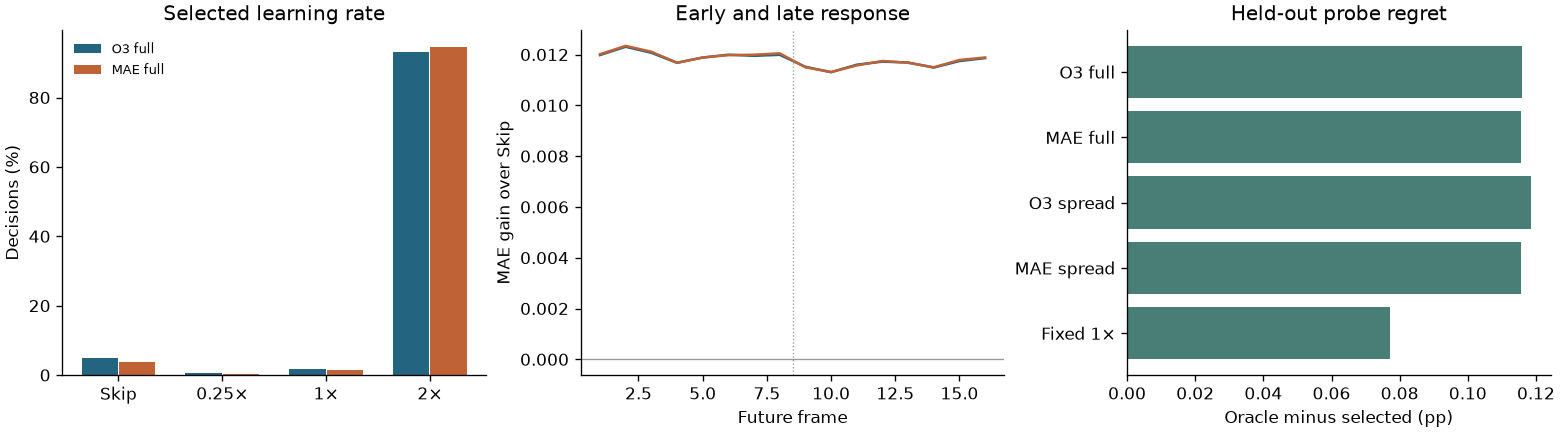

In [ ]:
# Snapshot from the paired state receipts.

## Example decision · seed 2026 · clip 04076a65-79b349d4 · frame 0

| LR | Mean future MAE | Window RankMe | 50/50 O3 gain | O3 choice | MAE choice | Audit MAE | Probe Q (%) | Forgetting (pp) |
|---|---:|---:|---:|:---:|:---:|---:|---:|---:|
| Skip | 0.936591 | 1.1906 | +0.000000 |  |  | 0.922121 | 60.847 | +0.000 |
| 0.25× | 0.936337 | 1.1903 | +0.000987 |  |  | 0.921897 | 60.762 | +0.073 |
| 1× | 0.935649 | 1.1892 | +0.003591 |  |  | 0.921304 | 60.793 | -0.190 |
| 2× | 0.934912 | 1.1877 | +0.006221 | ✓ | ✓ | 0.920700 | 60.655 | -0.297 |

## Inspect every candidate

Run the cell below to load the latest paired receipts. Filter the resulting table by seed, clip and origin.

In [ ]:
from pathlib import Path
import json
import pandas as pd

rel = Path("analysis/2026-11-09-one-step-mpc/mae-lookahead-a/results/cases")
folder = next(p / rel for p in (Path.cwd(), *Path.cwd().parents) if (p / rel).is_dir())
records = []
for path in sorted(folder.glob("*.json")):
    row = json.loads(path.read_text(encoding="utf-8"))
    for a, branch in enumerate(row["actions"]):
        losses = branch["loss"]
        records.append(dict(seed=row["seed"], clip=row["clip"], origin=row["offset"], lr=(0,.25,1,2)[a],
            future_loss=sum(losses)/16, early_gain=sum(x-y for x,y in zip(row["actions"][0]["loss"][:8], losses[:8]))/8,
            late_gain=sum(x-y for x,y in zip(row["actions"][0]["loss"][8:], losses[8:]))/8,
            rank=branch["rank"], o3_score=row["scores"]["O3 full"][a], loss_term=row["loss_terms"][a],
            rank_term=row["rank_terms"][a], o3_chosen=row["choices"]["O3 full"]==a,
            mae_chosen=row["choices"]["MAE full"]==a, audit_loss=sum(branch["audit"])/16,
            probe_accuracy=branch["q"], forgetting=branch["forgetting"]))
candidates = pd.DataFrame(records)
display(candidates.head(12))